# 04 · Modelos base: regresión logística y XGBoost (JAE)

**Objetivo:** construir dos modelos base y compararlos con exactamente el
mismo esquema de validación:

1. **Regresión logística** como línea base.
2. **XGBoost** para intentar superarla.

**Contexto de la competencia** (`competencia-crediticia-por-5-decimas`):

| Elemento | Valor |
| --- | --- |
| Variable objetivo | `SeriousDlqin2yrs`: 1 = morosidad grave (90 días o más de atraso en los siguientes 2 años); 0 = cumple |
| Métrica | AUC-ROC |
| Archivos | `train.csv` (105,000 filas), `test.csv` (45,000) y `sample_submission.csv` |
| Identificador | `Id` (no se usa como variable) |

**Punto de partida:** el EDA (`notebooks/02_eda.ipynb`) y la ingeniería de
variables (`notebooks/03_ingenieria_variables_jae.ipynb`, módulo
`src/features/engineering_jae.py`). Aquí no se repite el análisis
exploratorio; cada decisión de preprocesamiento remite a él.

**Referencia:** `notebooks/baseline_test.ipynb` (misma partición de
validación del equipo y bitácora compartida en `reports/experiments.csv`).

## Hallazgos del EDA que guían los modelos

| Tema | Hallazgo | Decisión en este notebook |
| --- | --- | --- |
| Clase positiva | 6.68 % (≈ 1 moroso por cada 14 clientes) | Validación estratificada; AUC como métrica; `scale_pos_weight` como experimento aparte |
| Variables numéricas | Las 10 son numéricas; utilización, `DebtRatio` e ingreso con asimetría de 56 a 120 | Recortes fijos + `log1p` para la logística; sin transformar para XGBoost |
| Variables categóricas | **No hay** | One-Hot Encoding no aplica |
| Códigos 96/98 en atrasos | 197 filas, siempre en las tres columnas | `NaN` + indicador `late_sentinel` |
| Faltantes | `MonthlyIncome` 19.8 % y `NumberOfDependents` 2.6 % (siempre junto con el ingreso); no son aleatorios | Indicadores `income_missing` y `dependents_missing`; imputación ⭐ B (edad + decil del monto de deuda) en la logística; `NaN` nativo en XGBoost |
| Ingreso 0 y 1 | 1,143 en 0 y 423 en 1 (valor de relleno) | Indicadores `income_zero` e `income_placeholder` |
| `DebtRatio` | Es un monto cuando falta el ingreso | Separado en `debt_ratio_valid` y `debt_amount` |
| Variables nuevas | Ingreso disponible (IV 0.161), ingreso por dependiente, atrasos agregados, perfil | Incluidas |
| Data leakage | Ninguna variable original la tiene; la imputación del ingreso con un modelo que use `DebtRatio` sí (EDA 10.8 c) | Se excluye esa imputación; todo lo aprendido se ajusta dentro de cada fold |

**Decisiones que se apartan del planteamiento original (y por qué):**
- **Escalado:** `StandardScaler` en lugar de `RobustScaler`. Los atípicos ya
  se recortan antes de escalar y en el notebook 03 ambos escaladores
  empataron.
- **Imputación de la logística:** en lugar de la mediana simple, el ingreso
  se imputa con la estrategia ⭐ B y los dependientes con la mediana de su
  grupo de edad (EDA, sección 10.3). El resto usa la mediana.
- **Semilla:** se usa la partición del equipo (`get_cv()`, semilla 985) en
  lugar de 42, para que los resultados sean comparables con la bitácora
  compartida fold por fold.
- ***Early stopping*:** el número de árboles se elige con un 10 % reservado
  del fold de **entrenamiento**, no con el fold de validación. Elegirlo
  con el fold de validación haría que el AUC reportado saliera
  ligeramente optimista.
- **Búsqueda de hiperparámetros de XGBoost:** búsqueda aleatoria con
  `ParameterSampler`, porque `RandomizedSearchCV` no permite *early
  stopping* por fold. Optuna no está entre las dependencias del proyecto.

## 0. Preparación del entorno

In [1]:
import logging
import sys
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, ParameterSampler
from sklearn.pipeline import Pipeline
from xgboost import DMatrix, XGBClassifier

# El notebook vive en notebooks/: se agrega src/ al path para importar los módulos
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from evaluation import RANDOM_STATE, get_cv, read_log  # noqa: E402
from evaluation.oof_jae import (  # noqa: E402
    ResultadoCV,
    evaluar_modelo,
    graficar_roc,
    graficar_roc_oof,
    registrar_en_bitacora,
    tabla_folds,
)
from features.engineering_jae import (  # noqa: E402
    ID,
    RAW_FEATURES,
    TARGET,
    FeatureConfig,
    build_preprocessor,
    prepare_fixed,
)

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

SEMILLA = RANDOM_STATE  # semilla compartida del equipo (985)
SALIDA = ROOT / "data" / "processed" / "jae"
print(f"Semilla: {SEMILLA}")

Semilla: 985


## 1. Carga de datos
Se cargan los tres archivos y se verifican dimensiones, tipos y la
proporción de la variable objetivo.

In [2]:
train_raw = pd.read_csv(ROOT / "data/raw/train.csv")
test_raw = pd.read_csv(ROOT / "data/raw/test.csv")
muestra = pd.read_csv(ROOT / "data/raw/sample_submission.csv")

pd.DataFrame(
    {
        "filas": [len(train_raw), len(test_raw), len(muestra)],
        "columnas": [train_raw.shape[1], test_raw.shape[1], muestra.shape[1]],
    },
    index=["train", "test", "sample_submission"],
)

,filas,columnas
train,105000,12
test,45000,11
sample_submission,45000,2


In [3]:
# Tipos de datos y faltantes por variable
pd.DataFrame(
    {
        "tipo": train_raw.dtypes.astype(str),
        "faltantes train (%)": train_raw.isna().mean() * 100,
        "faltantes test (%)": test_raw.isna().mean().reindex(train_raw.columns) * 100,
    }
).round(2)

,tipo,faltantes train (%),faltantes test (%)
Id,int64,0.00,0.00
SeriousDlqin2yrs,int64,0.00,NaN
RevolvingUtilizationOfUnsecuredLines,float64,0.00,0.00
age,int64,0.00,0.00
NumberOfTime30-59DaysPastDueNotWorse,int64,0.00,0.00
DebtRatio,float64,0.00,0.00
MonthlyIncome,float64,19.84,19.78
NumberOfOpenCreditLinesAndLoans,int64,0.00,0.00
NumberOfTimes90DaysLate,int64,0.00,0.00
NumberRealEstateLoansOrLines,int64,0.00,0.00


In [4]:
# Proporción de la clase objetivo
proporcion = train_raw[TARGET].value_counts().to_frame("clientes")
proporcion["%"] = proporcion["clientes"] / len(train_raw) * 100
proporcion.round(2)

,clientes,%
SeriousDlqin2yrs,,
0,97982,93.32
1,7018,6.68


**Lectura:** las cifras coinciden con el EDA: 105,000 filas en `train` y
45,000 en `test`, solo dos variables con faltantes y una clase positiva de
6.68 %. Todas las variables son numéricas.

## 2. Preparación
Se aplican las **transformaciones fijas** del EDA con `prepare_fixed()`:
códigos 96/98 a `NaN`, edad inválida a `NaN`, indicadores, recortes de
atípicos, separación de `DebtRatio` y llaves de grupo para la imputación.
Son deterministas (no aprenden nada de los datos), por eso se pueden aplicar
antes de la validación cruzada sin data leakage.

Lo que sí se aprende de los datos (imputaciones, cortes de deciles,
escalado) va dentro del `Pipeline` de cada modelo y se ajusta en cada
fold.

In [5]:
y = train_raw[TARGET]
X = prepare_fixed(train_raw.drop(columns=[TARGET, ID]))
X_test = prepare_fixed(test_raw.drop(columns=[ID]))

VARIABLES_NUMERICAS = list(RAW_FEATURES)
VARIABLES_CATEGORICAS: list[str] = []  # el conjunto no tiene variables categóricas

assert len(X) == len(train_raw) and len(X_test) == len(test_raw), "Cambiaron las filas"
print(f"X: {X.shape} · X_test: {X_test.shape} · y: {y.shape}")
print(f"Variables numéricas originales ({len(VARIABLES_NUMERICAS)}):", VARIABLES_NUMERICAS)
print("Variables categóricas:", VARIABLES_CATEGORICAS or "ninguna")

X: (105000, 37) · X_test: (45000, 37) · y: (105000,)
Variables numéricas originales (10): ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']
Variables categóricas: ninguna


**Variables que recibe cada modelo.** Las dos configuraciones salen del
módulo de ingeniería de variables:
- **Logística (`CONFIG_LINEAL`):** ingreso imputado con ⭐ B, ingreso
  disponible, ingreso por dependiente, indicadores, `log1p` en las
  variables con cola larga y `StandardScaler`.
- **XGBoost (`CONFIG_ARBOLES`):** las mismas variables construidas, sin
  escalar y **sin imputar**: el ingreso, los dependientes y la edad
  inválida quedan como `NaN` y XGBoost los maneja de forma nativa.

In [6]:
CONFIG_LINEAL = FeatureConfig()
CONFIG_ARBOLES = FeatureConfig(for_trees=True, impute_for_trees=False)

# Ajuste sobre todo train solo para listar las columnas de salida (no se evalúa aquí)
columnas_lineal = build_preprocessor(CONFIG_LINEAL).fit_transform(X, y).columns
X_arboles = build_preprocessor(CONFIG_ARBOLES).fit_transform(X, y)
print(f"Logística: {len(columnas_lineal)} variables\n", list(columnas_lineal))
print(f"\nXGBoost: {X_arboles.shape[1]} variables\n", list(X_arboles.columns))
print("\nFaltantes que XGBoost recibe como NaN:")
print(X_arboles.isna().sum()[lambda s: s > 0].to_string())

Logística: 21 variables
 ['income_imp_age_debt', 'per_dependent_income_imp_age_debt', 'debt_amount', 'debt_ratio_valid', 'late_30_59', 'late_60_89', 'late_90', 'util_clip', 'age', 'open_lines', 'real_estate', 'dependents', 'late_sentinel', 'income_missing', 'income_zero', 'income_placeholder', 'dependents_missing', 'util_gt1', 'util_zero', 'thin_file', 'disposable_income_imp_age_debt']

XGBoost: 23 variables
 ['income_clip', 'per_dependent_income_clip', 'debt_amount', 'debt_ratio_valid', 'late_30_59', 'late_60_89', 'late_90', 'disposable_income_clip', 'util_clip', 'age', 'open_lines', 'real_estate', 'dependents', 'late_sentinel', 'income_missing', 'income_zero', 'income_placeholder', 'dependents_missing', 'util_gt1', 'util_zero', 'thin_file', 'total_late', 'late_severity']

Faltantes que XGBoost recibe como NaN:
income_clip                  20828
per_dependent_income_clip    20828
disposable_income_clip       20828
age                              1
dependents                    2771


**Variables redundantes.** Se buscan pares con correlación de Spearman
alta (|ρ| ≥ 0.8), que afectan la interpretación de los coeficientes de la
logística (los árboles no se ven afectados).

In [7]:
spearman = X_arboles.corr(method="spearman")
pares = (
    spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1))
    .stack()
    .rename("Spearman")
    .to_frame()
)
pares_altos = pares[pares["Spearman"].abs() >= 0.8].sort_values(
    "Spearman", key=np.abs, ascending=False
)
pares_altos.round(3)

,,Spearman
total_late,late_severity,0.998
late_30_59,total_late,0.870
income_clip,disposable_income_clip,0.862
late_30_59,late_severity,0.840


**Lectura:** hay cuatro pares redundantes, todos por construcción:
- `total_late` y `late_severity` (0.998) y ambos con `late_30_59` (0.87 y
  0.84): son agregados de los mismos atrasos. Solo los recibe XGBoost, que
  no se ve afectado por la redundancia; la logística usa los tres atrasos
  por separado.
- `income_clip` e ingreso disponible (0.86): el ingreso disponible es el
  ingreso menos la deuda. En la logística, sus coeficientes se reparten
  entre ambos y deben leerse juntos (sección 4).

## 3. Esquema de validación
- `StratifiedKFold` de 5 folds con la semilla del equipo, **la misma
  partición para todos los experimentos** (y para la bitácora compartida).
- La función `evaluar_modelo()` (`src/evaluation/oof_jae.py`, con pruebas en
  `tests/test_oof_jae.py`) entrena un clon nuevo del modelo en cada fold y
  devuelve:
  - AUC por fold, promedio ± desviación estándar.
  - AUC de entrenamiento (para medir la brecha con validación).
  - AUC OOF global y las predicciones fuera de fold (*out-of-fold*): la
    probabilidad de cada cliente cuando estuvo en el fold de validación.
  - Para XGBoost, el número de árboles elegido por *early stopping* en cada
    fold.

In [8]:
cv = get_cv()
folds = pd.DataFrame(
    [
        {
            "fold": i,
            "filas entrenamiento": len(idx_tr),
            "filas validación": len(idx_va),
            "% morosos validación": y.iloc[idx_va].mean() * 100,
        }
        for i, (idx_tr, idx_va) in enumerate(cv.split(X, y), start=1)
    ]
).set_index("fold")
folds.round(3)

,filas entrenamiento,filas validación,% morosos validación
fold,,,
1,84000,21000,6.681
2,84000,21000,6.681
3,84000,21000,6.686
4,84000,21000,6.686
5,84000,21000,6.686


**Lectura:** los cinco folds tienen 21,000 clientes de validación y la
misma proporción de morosos (≈ 6.68 %): la estratificación funciona.

In [9]:
def mostrar_experimento(resultado: ResultadoCV) -> None:
    """Muestra la tabla de AUC por fold y la curva ROC de un experimento.

    Args:
        resultado: Resultado de ``evaluar_modelo``.
    """
    display(tabla_folds(resultado).round(4))
    fig, ax = plt.subplots(figsize=(6.5, 6))
    graficar_roc(resultado, ax=ax)
    plt.show()


resultados: dict[str, ResultadoCV] = {}

## 4. Modelo 1: regresión logística (línea base)

### Experimento 1a: configuración por omisión
`LogisticRegression` con sus valores por omisión (regularización L2 con
`C=1`). Solo se sube `max_iter` a 2,000 para garantizar la convergencia.
El preprocesamiento es el de `CONFIG_LINEAL`, dentro del `Pipeline`.

,AUC validación,AUC entrenamiento
fold 1,0.8527,0.8578
fold 2,0.8607,0.8564
fold 3,0.8547,0.8574
fold 4,0.8555,0.8578
fold 5,0.8607,0.8565
promedio,0.8568,0.8572
desv,0.0033,0.0006


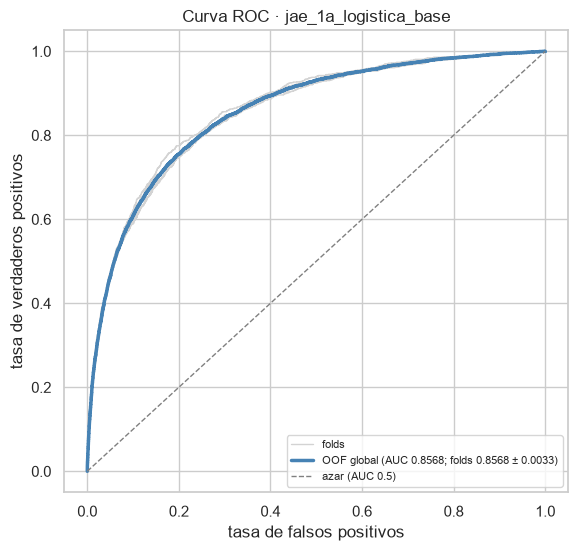

In [10]:
def logistica(**parametros: object) -> Pipeline:
    """Arma el pipeline de preprocesamiento lineal + regresión logística.

    Args:
        **parametros: Parámetros de ``LogisticRegression``.

    Returns:
        Pipeline sin ajustar.
    """
    clasificador = LogisticRegression(max_iter=2000, random_state=SEMILLA, **parametros)
    return Pipeline([("prep", build_preprocessor(CONFIG_LINEAL)), ("clf", clasificador)])


resultados["1a"] = evaluar_modelo(logistica(), X, y, "jae_1a_logistica_base")
mostrar_experimento(resultados["1a"])

**Lectura del experimento 1a:**
- **Nivel:** AUC de **0.8568 ± 0.0033**. Con las 10 variables crudas, la
  misma logística del equipo (`logreg_raw`) logra 0.699 en estos mismos
  folds: la limpieza y la ingeniería de variables suman +0.158.
- **Estabilidad:** los folds van de 0.8527 a 0.8607. Los folds 2 y 5
  son los más fáciles para todos los modelos de este notebook, por eso las
  comparaciones se hacen fold por fold.
- **Brecha entrenamiento-validación:** 0.0003. No hay sobreajuste: el
  modelo es estable, pero su límite es el **sesgo** (solo capta relaciones
  lineales en las variables transformadas).

### Experimento 1b: ajuste de la regularización
Búsqueda en rejilla con la misma partición: `C` de 0.001 a 10 y
penalización L1 (`l1_ratio=1`) o L2 (`l1_ratio=0`). Se usa el *solver*
`liblinear`, que admite ambas penalizaciones. Un `C` menor significa más
regularización.

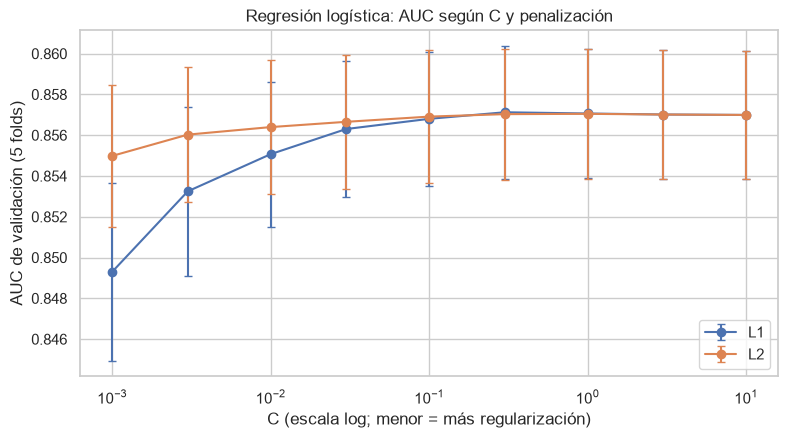

Búsqueda: 18 combinaciones en 36 s
Mejores parámetros: {'clf__C': 0.3, 'clf__l1_ratio': 1.0}


penalización,L1,L2
param_clf__C,,
0.001,0.8493,0.8550
0.003,0.8532,0.8560
0.010,0.8551,0.8564
0.030,0.8563,0.8567
0.100,0.8568,0.8569
0.300,0.8571,0.8570
1.000,0.8571,0.8570
3.000,0.8570,0.8570
10.000,0.8570,0.8570


In [11]:
REJILLA_LOGISTICA = {
    "clf__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    "clf__l1_ratio": [0.0, 1.0],
}
busqueda_1b = GridSearchCV(
    logistica(solver="liblinear"),
    REJILLA_LOGISTICA,
    scoring="roc_auc",
    cv=get_cv(),
    return_train_score=True,
)
inicio = time.perf_counter()
busqueda_1b.fit(X, y)
tiempo_busqueda_1b = time.perf_counter() - inicio

rejilla_1b = pd.DataFrame(busqueda_1b.cv_results_)
rejilla_1b["penalización"] = rejilla_1b["param_clf__l1_ratio"].map({0.0: "L2", 1.0: "L1"})
fig, ax = plt.subplots(figsize=(9, 4.5))
for penalizacion, datos in rejilla_1b.groupby("penalización"):
    ax.errorbar(
        datos["param_clf__C"].astype(float),
        datos["mean_test_score"],
        yerr=datos["std_test_score"],
        marker="o",
        capsize=3,
        label=penalizacion,
    )
ax.set_xscale("log")
ax.set_xlabel("C (escala log; menor = más regularización)")
ax.set_ylabel("AUC de validación (5 folds)")
ax.set_title("Regresión logística: AUC según C y penalización")
ax.legend()
plt.show()
print(f"Búsqueda: {len(rejilla_1b)} combinaciones en {tiempo_busqueda_1b:.0f} s")
print("Mejores parámetros:", busqueda_1b.best_params_)
rejilla_1b.pivot_table(
    index="param_clf__C", columns="penalización", values="mean_test_score"
).round(4)

,AUC validación,AUC entrenamiento
fold 1,0.8533,0.8580
fold 2,0.8610,0.8567
fold 3,0.8548,0.8578
fold 4,0.8555,0.8581
fold 5,0.8610,0.8565
promedio,0.8571,0.8574
desv,0.0033,0.0007


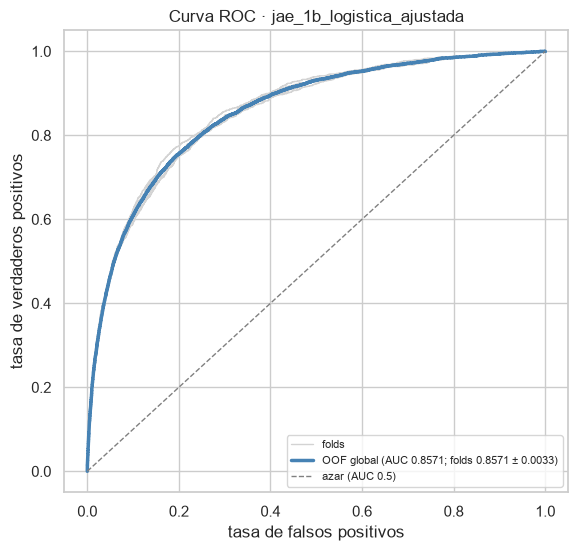

In [12]:
parametros_1b = {
    clave.replace("clf__", ""): valor for clave, valor in busqueda_1b.best_params_.items()
}
resultados["1b"] = evaluar_modelo(
    logistica(solver="liblinear", **parametros_1b), X, y, "jae_1b_logistica_ajustada"
)
mostrar_experimento(resultados["1b"])

**Lectura del experimento 1b:**
- **La regularización casi no importa:** con `C ≥ 0.1` el AUC queda entre
  0.8568 y 0.8571, con L1 o L2. Solo la regularización fuerte (`C ≤ 0.01`)
  empeora el modelo, sobre todo con L1 (0.8493 con `C=0.001`).
- **Mejor combinación:** L1 con `C=0.3`, AUC **0.8571 ± 0.0033**: +0.0003
  sobre 1a, diez veces menor que la desviación entre folds. Es un
  empate en la práctica.
- **Brecha:** 0.0003, igual que 1a. Con 105,000 clientes y 21 variables,
  la logística no tiene capacidad para sobreajustar; por eso regularizar no
  ayuda.
- **Lo que sí aporta L1:** selección de variables. Lleva a cero
  `dependents_missing` y `thin_file`, y casi a cero el ingreso imputado
  (−0.013), cuya información ya está en el ingreso disponible y el ingreso
  por dependiente.

### Coeficientes de la mejor regresión logística
Se reentrena el mejor experimento lineal con todo `train`. Como las
variables continuas están estandarizadas, el coeficiente mide el cambio en
el logaritmo de las momios (*log-odds*) por una desviación estándar; en los
indicadores, por pasar de 0 a 1. `exp(coef)` es la razón de momios.

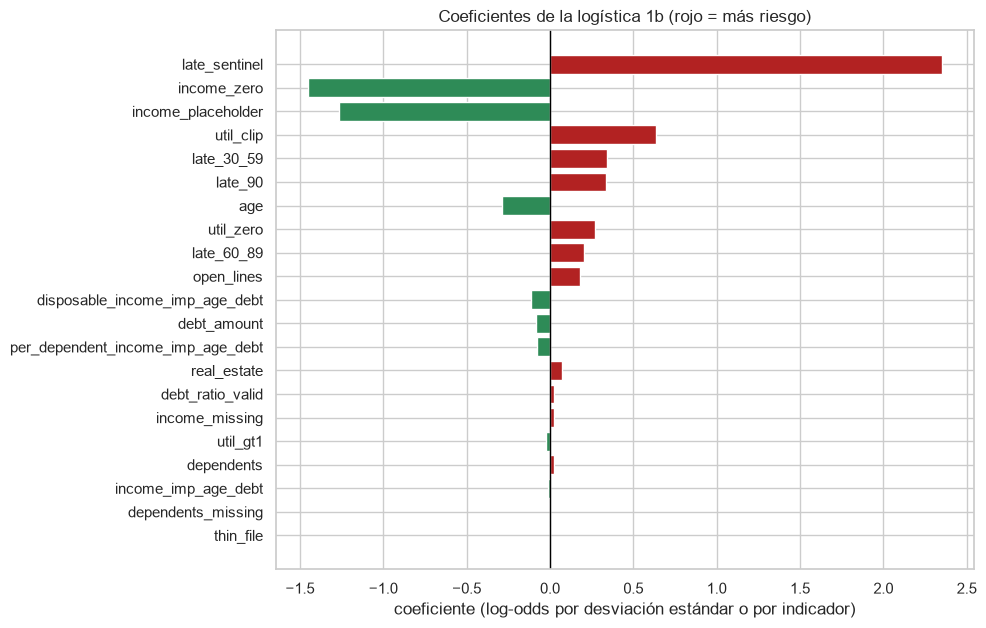

Experimento con mejor AUC lineal: 1b


,coeficiente,razón de momios
late_sentinel,2.352,10.503
income_zero,-1.453,0.234
income_placeholder,-1.266,0.282
util_clip,0.634,1.886
late_30_59,0.339,1.404
late_90,0.338,1.402
age,-0.289,0.749
util_zero,0.269,1.309
late_60_89,0.202,1.224
open_lines,0.182,1.200


In [13]:
mejor_lineal = max(("1a", "1b"), key=lambda k: resultados[k].auc_media)
parametros_lineal = {} if mejor_lineal == "1a" else {"solver": "liblinear", **parametros_1b}
modelo_lineal = logistica(**parametros_lineal).fit(X, y)
nombres_lineal = modelo_lineal[:-1].transform(X.head()).columns
coeficientes = pd.DataFrame(
    {"coeficiente": modelo_lineal[-1].coef_[0]}, index=nombres_lineal
)
coeficientes["razón de momios"] = np.exp(coeficientes["coeficiente"])
coeficientes = coeficientes.reindex(
    coeficientes["coeficiente"].abs().sort_values(ascending=False).index
)

fig, ax = plt.subplots(figsize=(9, 7))
orden = coeficientes["coeficiente"].iloc[::-1]
ax.barh(orden.index, orden, color=["firebrick" if c > 0 else "seagreen" for c in orden])
ax.axvline(0, color="black", lw=1)
ax.set_title(f"Coeficientes de la logística {mejor_lineal} (rojo = más riesgo)")
ax.set_xlabel("coeficiente (log-odds por desviación estándar o por indicador)")
plt.show()
print(f"Experimento con mejor AUC lineal: {mejor_lineal}")
coeficientes.head(12).round(3)

**Lectura de los coeficientes en el contexto de riesgo crediticio:**
- **Códigos 96/98 (`late_sentinel`): el factor de riesgo más fuerte.**
  Multiplica las momios de morosidad por 10.5. En los datos, el 56.9 % de
  esos 197 clientes cae en morosidad.
- **Utilización (`util_clip`):** razón de momios de 1.89 por cada
  desviación estándar. Usar más la línea de crédito es la señal continua de
  riesgo más fuerte.
- **Atrasos previos:** 30–59 días (1.40), 90 días o más (1.40) y 60–89 días
  (1.22). Todos suman riesgo, aun con los demás atrasos en el modelo.
- **Edad:** 0.75 por desviación estándar: a mayor edad, menor riesgo.
- **Ingreso 0 y 1 (`income_zero`, `income_placeholder`):** reducen el
  riesgo (0.23 y 0.28). Coincide con sus tasas reales de morosidad, 4.2 % y
  3.3 %, debajo del 6.68 % general. El coeficiente es grande porque también
  compensa el valor extremo que toman el ingreso disponible y el ingreso
  por dependiente en esos clientes; no se interpreta por separado.
- **`util_zero` aumenta el riesgo (1.31)** una vez que se considera la
  utilización: no usar la línea es menos seguro que usarla poco (0–0.1),
  como mostró el WoE del EDA.
- **Ingreso disponible:** 0.90 por desviación estándar. Más capacidad de
  pago, menos riesgo.
- Las variables de ingreso están correlacionadas entre sí, así que sus
  coeficientes individuales son menos confiables que los de atrasos y
  utilización.

## 5. Modelo 2: XGBoost

### Experimento 2a: hiperparámetros iniciales
`learning_rate=0.05` y `max_depth=4`, con hasta 3,000 árboles y *early
stopping* de 100 rondas. En cada fold, el número de árboles se elige con
un 10 % reservado del fold de entrenamiento; el fold de validación
solo se usa para medir. Las variables van sin escalar y con `NaN` nativo.

,AUC validación,AUC entrenamiento,n.º de árboles
fold 1,0.8613,0.8827,248.0000
fold 2,0.8670,0.8832,297.0000
fold 3,0.8644,0.8811,233.0000
fold 4,0.8628,0.8785,186.0000
fold 5,0.8690,0.8804,241.0000
promedio,0.8649,0.8812,241.0000
desv,0.0028,0.0017,35.4232


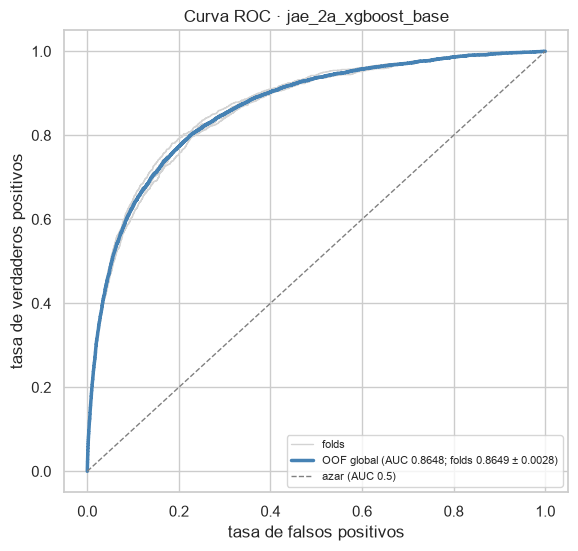

In [14]:
RONDAS_PARADA = 100


def xgboost_modelo(**parametros: object) -> Pipeline:
    """Arma el pipeline de preprocesamiento para árboles + XGBoost.

    Args:
        **parametros: Parámetros de ``XGBClassifier`` que reemplazan a los
            iniciales.

    Returns:
        Pipeline sin ajustar.
    """
    base = {
        "n_estimators": 3000,
        "learning_rate": 0.05,
        "max_depth": 4,
        "eval_metric": "auc",
        "tree_method": "hist",
        "random_state": SEMILLA,
        "n_jobs": -1,
    }
    base.update(parametros)
    return Pipeline(
        [("prep", build_preprocessor(CONFIG_ARBOLES)), ("clf", XGBClassifier(**base))]
    )


resultados["2a"] = evaluar_modelo(
    xgboost_modelo(),
    X,
    y,
    "jae_2a_xgboost_base",
    early_stopping_rounds=RONDAS_PARADA,
)
mostrar_experimento(resultados["2a"])

**Lectura del experimento 2a:**
- **Nivel:** AUC de **0.8649 ± 0.0028**, +0.0081 sobre la mejor logística.
  Supera también al LightGBM por omisión del equipo (0.8636 en estos mismos
  folds).
- **Estabilidad:** los folds van de 0.8613 a 0.8690, con el mismo patrón
  que la logística (2 y 5 más altos).
- **Brecha:** 0.0163 (0.8812 en entrenamiento). Los árboles aprenden
  detalles del entrenamiento que no se generalizan por completo, pero aun
  así validan mejor que la logística: la brecha es el precio de reducir el
  sesgo.
- ***Early stopping*:** elige entre 186 y 297 árboles (241 en promedio).
  Con `learning_rate=0.05`, el modelo deja de mejorar pronto: la señal se
  captura con árboles poco profundos.

### Experimento 2b: ajuste de hiperparámetros
Búsqueda aleatoria de 30 combinaciones sobre `max_depth`,
`min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda` y
`gamma`, con la misma partición y el mismo *early stopping*.
`learning_rate` se mantiene en 0.05 para que la comparación sea solo de la
forma de los árboles.

**Advertencia:** elegir la mejor de 30 combinaciones con los mismos
folds con los que se reporta el AUC introduce un sesgo optimista
pequeño. Por eso, la mejora sobre 2a se compara con la variabilidad entre
folds (sección 6).

In [15]:
ESPACIO_XGBOOST = {
    "max_depth": [3, 4, 5, 6, 7, 8],
    "min_child_weight": [1, 3, 5, 10, 20, 50],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "reg_lambda": [0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
    "gamma": [0.0, 0.1, 0.5, 1.0, 2.0, 5.0],
}
N_CANDIDATOS = 30
candidatos = list(
    ParameterSampler(ESPACIO_XGBOOST, n_iter=N_CANDIDATOS, random_state=SEMILLA)
)

inicio = time.perf_counter()
busqueda_2b: list[tuple[dict, ResultadoCV]] = []
for i, parametros in enumerate(candidatos, start=1):
    resultado = evaluar_modelo(
        xgboost_modelo(**parametros),
        X,
        y,
        f"candidato {i}",
        early_stopping_rounds=RONDAS_PARADA,
    )
    busqueda_2b.append((parametros, resultado))
tiempo_busqueda_2b = time.perf_counter() - inicio

tabla_2b = pd.DataFrame(
    [
        {
            **parametros,
            "AUC": r.auc_media,
            "desv": r.auc_std,
            "brecha": r.brecha,
            "árboles (media)": np.mean(r.n_arboles),
        }
        for parametros, r in busqueda_2b
    ]
).sort_values("AUC", ascending=False)
print(f"Búsqueda: {N_CANDIDATOS} combinaciones en {tiempo_busqueda_2b:.0f} s")
print(f"AUC de 2a (referencia): {resultados['2a'].auc_media:.4f}")
tabla_2b.head(10).round(4)

Búsqueda: 30 combinaciones en 128 s
AUC de 2a (referencia): 0.8649


,subsample,reg_lambda,min_child_weight,max_depth,gamma,colsample_bytree,AUC,desv,brecha,árboles (media)
15,0.6,10.0,10,6,0.5,0.7,0.8659,0.0032,0.0179,157.6
7,0.6,10.0,10,4,5.0,0.9,0.8657,0.0028,0.0071,386.2
26,0.8,0.1,10,5,0.5,1.0,0.8655,0.0028,0.0173,151.2
11,0.8,0.5,5,7,5.0,1.0,0.8655,0.0025,0.0193,194.4
10,0.9,20.0,1,6,0.0,1.0,0.8654,0.0031,0.0225,165.2
8,0.8,2.0,20,4,0.1,1.0,0.8654,0.0030,0.0134,272.8
24,1.0,10.0,20,5,1.0,0.9,0.8653,0.0029,0.0132,164.4
14,0.6,1.0,10,5,2.0,1.0,0.8653,0.0028,0.0182,189.0
9,0.6,2.0,5,3,1.0,0.7,0.8653,0.0032,0.0086,294.8
4,0.8,1.0,50,7,0.5,0.9,0.8651,0.0027,0.0154,138.0


Mejores parámetros: {'subsample': 0.6, 'reg_lambda': 10.0, 'min_child_weight': 10, 'max_depth': 6, 'gamma': 0.5, 'colsample_bytree': 0.7}


,AUC validación,AUC entrenamiento,n.º de árboles
fold 1,0.8622,0.8871,188.0000
fold 2,0.8686,0.8837,173.0000
fold 3,0.8649,0.8814,125.0000
fold 4,0.8630,0.8838,152.0000
fold 5,0.8705,0.8829,150.0000
promedio,0.8659,0.8838,157.6000
desv,0.0032,0.0019,21.5091


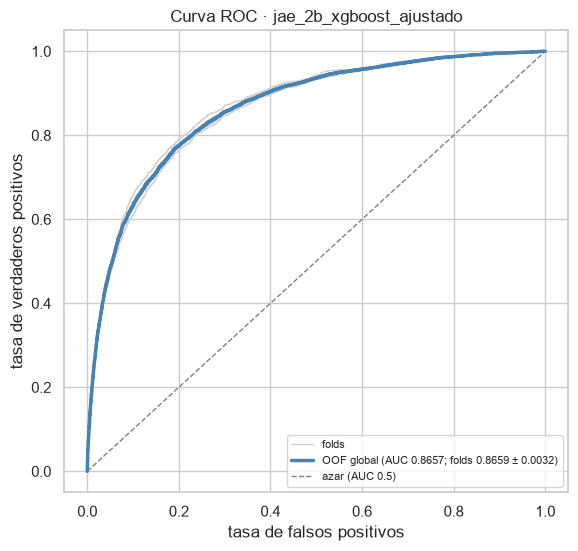

In [16]:
parametros_2b, mejor_candidato = max(busqueda_2b, key=lambda par: par[1].auc_media)
resultados["2b"] = replace(mejor_candidato, nombre="jae_2b_xgboost_ajustado")
print("Mejores parámetros:", parametros_2b)
mostrar_experimento(resultados["2b"])

**Lectura del experimento 2b:**
- **Mejor combinación:** `max_depth=6`, `min_child_weight=10`,
  `subsample=0.6`, `colsample_bytree=0.7`, `reg_lambda=10` y `gamma=0.5`.
  Árboles más profundos, pero con más regularización y muestreo.
- **Nivel:** AUC de **0.8659 ± 0.0032**, +0.0010 sobre 2a, y gana en los 5
  folds.
- **Cautela:** las 10 mejores combinaciones quedan entre 0.8651 y 0.8659:
  la superficie es plana y elegir la mejor de 30 con los mismos folds
  infla un poco el resultado. La mejora real sobre 2a probablemente es
  menor a 0.001.
- **Brecha:** 0.0179, un poco mayor que 2a, con menos árboles (158 en
  promedio) porque cada uno es más profundo.
- Las combinaciones con mucha regularización (`reg_lambda=10`,
  `gamma=5`) tienen la menor brecha (0.0071) con casi el mismo AUC
  (0.8657): son una alternativa más conservadora.

### Experimento 2c: `scale_pos_weight` (desbalance)
Con 6.68 % de morosos, `scale_pos_weight = negativos / positivos ≈ 14`
pesa más los errores en la clase positiva. Se prueba sobre los mejores
parámetros de 2b, cambiando solo esto.

scale_pos_weight = 13.96


,AUC validación,AUC entrenamiento,n.º de árboles
fold 1,0.8621,0.8811,54.0000
fold 2,0.8675,0.8831,72.0000
fold 3,0.8629,0.8879,91.0000
fold 4,0.8627,0.8869,84.0000
fold 5,0.8680,0.8757,35.0000
promedio,0.8646,0.8829,67.2000
desv,0.0025,0.0044,20.4098


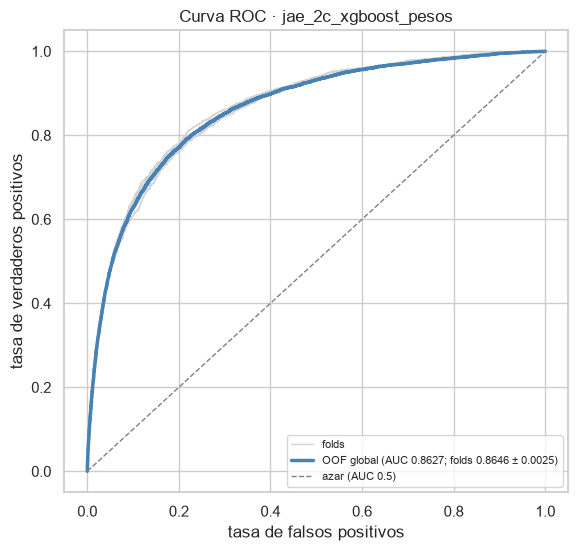

In [17]:
peso_positivos = float((y == 0).sum() / (y == 1).sum())
print(f"scale_pos_weight = {peso_positivos:.2f}")
resultados["2c"] = evaluar_modelo(
    xgboost_modelo(**parametros_2b, scale_pos_weight=peso_positivos),
    X,
    y,
    "jae_2c_xgboost_pesos",
    early_stopping_rounds=RONDAS_PARADA,
)
mostrar_experimento(resultados["2c"])

**Lectura del experimento 2c:**
- **`scale_pos_weight` no mejora el AUC:** 0.8646 ± 0.0025 contra 0.8659
  de 2b (−0.0013).
- **Empeora el AUC OOF global** (0.8627 contra 0.8657). Al pesar 14 veces
  más a los morosos, las probabilidades se inflan de forma distinta en cada
  fold; dentro de cada fold el orden se conserva, pero al juntarlas
  se mezclan peor.
- El *early stopping* se detiene muy pronto (67 árboles en promedio).
- El AUC solo mide el **orden** de los clientes, y reponderar las clases no
  cambia ese orden de forma útil. Además, las probabilidades dejan de estar
  calibradas. **Se descarta.**

### Importancia de variables y valores SHAP
Se reentrena el mejor XGBoost con todo `train`, con el número promedio de
árboles elegido por *early stopping* en sus folds.
- **Ganancia (*gain*):** cuánto mejora la función de pérdida, en promedio,
  cada vez que el modelo usa la variable para dividir.
- **SHAP:** contribución de cada variable a la predicción de cada cliente
  (en *log-odds*). Se calculan con `pred_contribs=True` de XGBoost, que
  implementa TreeSHAP sin depender de la librería `shap`.

Experimento con mejor AUC de XGBoost: 2b (158 árboles)


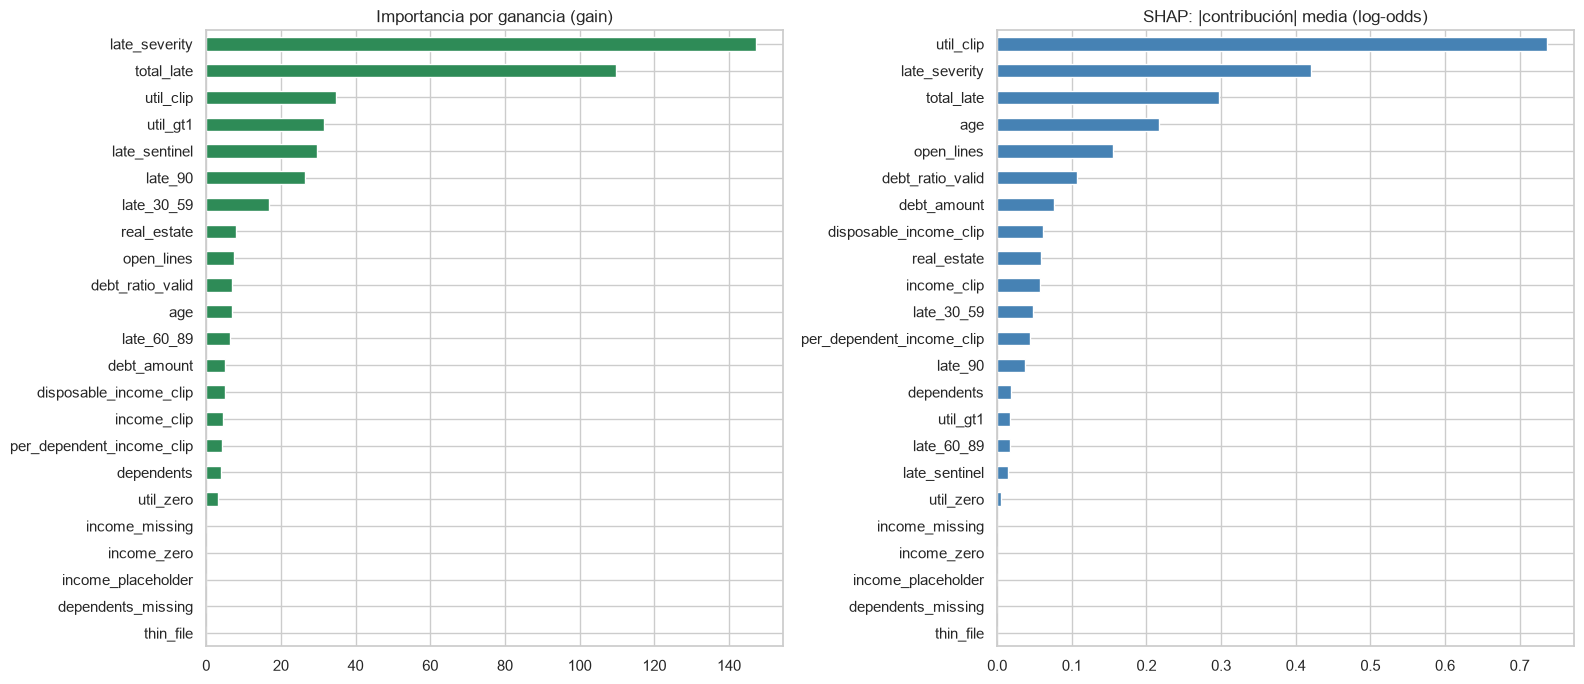

In [18]:
mejor_xgboost = max(("2a", "2b", "2c"), key=lambda k: resultados[k].auc_media)
parametros_xgboost = {
    "2a": {},
    "2b": parametros_2b,
    "2c": {**parametros_2b, "scale_pos_weight": peso_positivos},
}[mejor_xgboost]
arboles_finales = int(round(np.mean(resultados[mejor_xgboost].n_arboles)))
modelo_arboles = xgboost_modelo(**parametros_xgboost, n_estimators=arboles_finales)
modelo_arboles.fit(X, y)
print(f"Experimento con mejor AUC de XGBoost: {mejor_xgboost} ({arboles_finales} árboles)")

X_arboles_completo = modelo_arboles[:-1].transform(X)
booster = modelo_arboles[-1].get_booster()
ganancia = (
    pd.Series(booster.get_score(importance_type="gain"))
    .reindex(X_arboles_completo.columns)
    .fillna(0.0)
    .sort_values()
)

muestra_shap = X_arboles_completo.sample(10_000, random_state=SEMILLA)
contribuciones = booster.predict(DMatrix(muestra_shap), pred_contribs=True)
shap_valores = pd.DataFrame(contribuciones[:, :-1], columns=muestra_shap.columns)
shap_medio = shap_valores.abs().mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ganancia.plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Importancia por ganancia (gain)")
shap_medio.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("SHAP: |contribución| media (log-odds)")
plt.tight_layout()
plt.show()

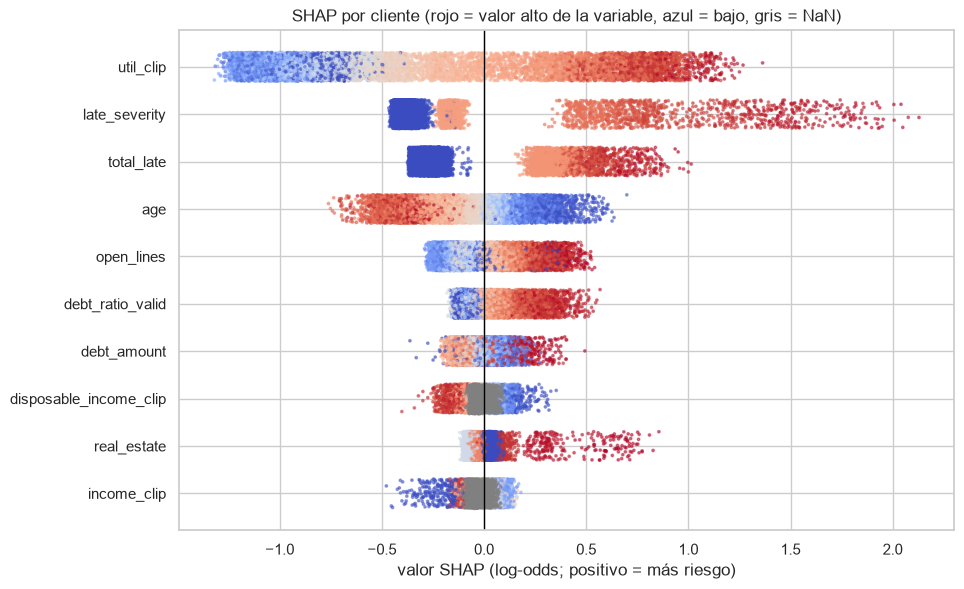

In [19]:
# Gráfica tipo enjambre (beeswarm) de las 10 variables con más contribución
principales = shap_medio.index[::-1][:10]
fig, ax = plt.subplots(figsize=(10, 6.5))
rng = np.random.default_rng(SEMILLA)
for posicion, variable in enumerate(principales[::-1]):
    valores = muestra_shap[variable]
    # Color por percentil del valor de la variable; los NaN se pintan en gris
    percentil = valores.rank(pct=True)
    dispersion = rng.uniform(-0.3, 0.3, size=len(valores))
    ax.scatter(
        shap_valores[variable],
        posicion + dispersion,
        c=percentil.fillna(0.5),
        cmap="coolwarm",
        s=3,
        alpha=0.5,
    )
    faltante = valores.isna().to_numpy()
    if faltante.any():
        ax.scatter(
            shap_valores.loc[faltante, variable],
            posicion + dispersion[faltante],
            color="gray",
            s=3,
            alpha=0.5,
        )
ax.set_yticks(range(len(principales)))
ax.set_yticklabels(principales[::-1])
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("valor SHAP (log-odds; positivo = más riesgo)")
ax.set_title("SHAP por cliente (rojo = valor alto de la variable, azul = bajo, gris = NaN)")
plt.show()

**Lectura de la importancia y de SHAP:**
- **Las dos medidas coinciden en el núcleo:** utilización, atrasos
  (`late_severity`, `total_late`) y edad. Es el mismo eje de riesgo que
  encontró el PCA del EDA (PC1).
- **Difieren en el orden:** la ganancia pone primero a los atrasos, porque
  pocas divisiones en ellos separan mucho; SHAP pone primero a la
  utilización, porque afecta la predicción de todos los clientes, no solo
  de los que tienen atrasos.
- **Dirección (enjambre):**
  - Utilización alta (rojo) sube el riesgo hasta +1.2 en *log-odds*; baja
    (azul) lo reduce hasta −1.3.
  - Cualquier atraso sube el riesgo; no tenerlo lo reduce de forma pareja.
  - Edad alta reduce el riesgo; edad baja lo aumenta.
  - Más líneas de crédito abiertas e hipotecas (`real_estate`) suben el
    riesgo, y `debt_ratio_valid` alto también.
  - El ingreso faltante (gris) queda cerca de 0: XGBoost lo envía a una
    rama propia sin sesgarlo hacia arriba ni hacia abajo.
- **Los indicadores no aportan a XGBoost** (`income_missing`,
  `income_zero`, `income_placeholder`, `thin_file`): el árbol deduce esa
  información de los `NaN` y de las variables originales. Sí son útiles
  para la logística.

## 6. Comparación de modelos

In [20]:
comparacion = pd.DataFrame([r.resumen() for r in resultados.values()]).set_index(
    "experimento"
)
comparacion.round(4)

,AUC entrenamiento,AUC validación (media),AUC validación (desv),AUC OOF global,brecha,tiempo (s)
experimento,,,,,,
jae_1a_logistica_base,0.8572,0.8568,0.0033,0.8568,0.0003,1.3388
jae_1b_logistica_ajustada,0.8574,0.8571,0.0033,0.8571,0.0003,3.7028
jae_2a_xgboost_base,0.8812,0.8649,0.0028,0.8648,0.0163,4.2867
jae_2b_xgboost_ajustado,0.8838,0.8659,0.0032,0.8657,0.0179,4.4059
jae_2c_xgboost_pesos,0.8829,0.8646,0.0025,0.8627,0.0183,3.0191


**Referencia del equipo.** La bitácora compartida usa la misma partición,
así que sus resultados son comparables directamente.

In [21]:
referencias = ["logreg_raw", "gbm_raw", "baseline_lightgbm"]
bitacora = read_log()
bitacora[bitacora["nombre"].isin(referencias)][
    ["nombre", "features", "modelo", "cv_auc_mean", "cv_auc_std", "kaggle_score"]
]

,nombre,features,modelo,cv_auc_mean,cv_auc_std,kaggle_score
0,logreg_raw,10 columnas crudas (sin ingeniería),imputar + escalar + clf,0.69931,0.00569,NaN
1,gbm_raw,10 columnas crudas (sin ingeniería),LGBMClassifier,0.86354,0.00229,0.87726
2,baseline_lightgbm,prepare() - 28 columnas,LGBMClassifier,0.86355,0.00242,0.87884


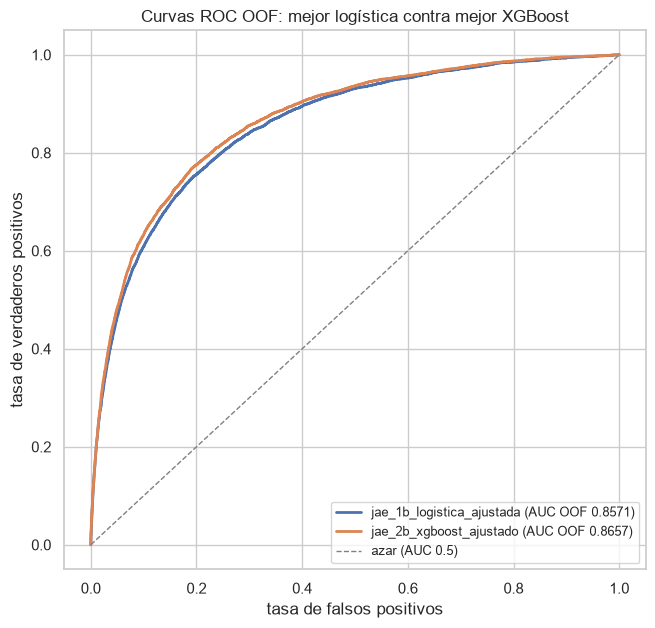

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 7))
graficar_roc_oof([resultados[mejor_lineal], resultados[mejor_xgboost]], y, ax=ax)
ax.set_title("Curvas ROC OOF: mejor logística contra mejor XGBoost")
plt.show()

**¿La mejora de XGBoost es real o es ruido?** Como los dos modelos usan los
mismos folds, la comparación es pareada: se resta el AUC fold por
fold. Si la diferencia es mayor que su propia variabilidad y gana en los
5 folds, no es ruido.

In [23]:
diferencia = resultados[mejor_xgboost].auc_folds - resultados[mejor_lineal].auc_folds
pareada = pd.DataFrame(
    {
        f"logística {mejor_lineal}": resultados[mejor_lineal].auc_folds,
        f"XGBoost {mejor_xgboost}": resultados[mejor_xgboost].auc_folds,
        "diferencia": diferencia,
    },
    index=[f"fold {i}" for i in range(1, 6)],
)
display(pareada.round(4))
print(f"Diferencia media: {diferencia.mean():+.4f} · desviación: {diferencia.std():.4f}")
print(f"Folds en que gana XGBoost: {(diferencia > 0).sum()}/5")
print(
    "Desviación entre folds de cada modelo: "
    f"{resultados[mejor_lineal].auc_std:.4f} y {resultados[mejor_xgboost].auc_std:.4f}"
)

# Y entre experimentos de XGBoost: ¿2b supera a 2a de forma consistente?
diferencia_2b = resultados["2b"].auc_folds - resultados["2a"].auc_folds
print(
    f"\n2b contra 2a: {diferencia_2b.mean():+.4f} "
    f"(gana en {(diferencia_2b > 0).sum()}/5 folds)"
)

,logística 1b,XGBoost 2b,diferencia
fold 1,0.8533,0.8622,0.0089
fold 2,0.8610,0.8686,0.0076
fold 3,0.8548,0.8649,0.0101
fold 4,0.8555,0.8630,0.0075
fold 5,0.8610,0.8705,0.0095


Diferencia media: +0.0087 · desviación: 0.0010
Folds en que gana XGBoost: 5/5
Desviación entre folds de cada modelo: 0.0033 y 0.0032

2b contra 2a: +0.0010 (gana en 5/5 folds)


**Lectura de la comparación:**
- **XGBoost supera a la logística de forma real, no por ruido:** +0.0087
  de AUC en promedio, gana en los 5 folds y la diferencia apenas varía
  entre folds (desviación 0.0010). La mejora es casi tres veces la
  desviación entre folds de cada modelo (≈ 0.0033).
- **Entre los XGBoost, las diferencias son pequeñas:** 2b supera a 2a por
  +0.0010 en los 5 folds, pero con el sesgo de la búsqueda; 2c queda
  abajo.
- **Frente al equipo:** 2b (0.8659) supera al LightGBM por omisión con
  `prepare()` (0.8636) por +0.0023, en los mismos folds. Es menor que la
  desviación entre folds y la bitácora no guarda el AUC por fold de
  ese modelo, así que no se puede afirmar que sea una mejora real.
- **Compromiso sesgo-varianza:** la logística tiene brecha casi nula pero
  AUC menor (**sesgo alto**); XGBoost tiene brecha de 0.018 (**más
  varianza**) pero valida mejor en todos los folds. Su varianza está
  controlada: la desviación entre folds es igual a la de la logística.
- **Tiempo:** todos los experimentos tardan menos de 5 s por validación
  cruzada; el costo está en las búsquedas (38 s para la logística y 124 s
  para XGBoost).
- **Calibración:** la métrica es AUC, que solo depende del orden, así que no
  es necesario calibrar. Aun así, la probabilidad media en `test` del modelo
  elegido (0.0665) coincide con la tasa de morosidad de `train` (0.0668).

**Recomendación: XGBoost 2b** como modelo de entrega. Si se prefiere un
modelo más conservador, la combinación con `reg_lambda=10` y `gamma=5`
tiene casi el mismo AUC con la menor brecha.

**Registro en la bitácora del equipo.** Cada experimento se agrega a
`reports/experiments.csv`; si el notebook se vuelve a correr, el registro
se reemplaza en lugar de duplicarse.

In [24]:
DESCRIPCIONES = {
    "1a": ("engineering_jae lineal (B, log1p, Standard)", "LogisticRegression C=1 L2"),
    "1b": (
        "engineering_jae lineal (B, log1p, Standard)",
        f"LogisticRegression liblinear {parametros_1b}",
    ),
    "2a": ("engineering_jae árboles (NaN nativo)", "XGBoost lr=0.05 depth=4 + ES"),
    "2b": ("engineering_jae árboles (NaN nativo)", f"XGBoost {parametros_2b} + ES"),
    "2c": (
        "engineering_jae árboles (NaN nativo)",
        f"XGBoost 2b + scale_pos_weight={peso_positivos:.1f}",
    ),
}
for clave, resultado in resultados.items():
    features, modelo = DESCRIPCIONES[clave]
    registrar_en_bitacora(
        resultado,
        features=features,
        modelo=modelo,
        notas=f"notebooks/04_modelos_base_jae; AUC OOF {resultado.auc_oof:.4f}",
    )
read_log().sort_values("cv_auc_mean", ascending=False)[
    ["nombre", "modelo", "cv_auc_mean", "cv_auc_std", "kaggle_score"]
]

,nombre,modelo,cv_auc_mean,cv_auc_std,kaggle_score
6,jae_2b_xgboost_ajustado,"XGBoost {'subsample': 0.6, 'reg_lambda': 10.0,...",0.86586,0.00322,NaN
5,jae_2a_xgboost_base,XGBoost lr=0.05 depth=4 + ES,0.86489,0.00275,NaN
7,jae_2c_xgboost_pesos,XGBoost 2b + scale_pos_weight=14.0,0.86464,0.00254,NaN
2,baseline_lightgbm,LGBMClassifier,0.86355,0.00242,0.87884
1,gbm_raw,LGBMClassifier,0.86354,0.00229,0.87726
4,jae_1b_logistica_ajustada,"LogisticRegression liblinear {'C': 0.3, 'l1_ra...",0.85712,0.00327,NaN
3,jae_1a_logistica_base,LogisticRegression C=1 L2,0.85682,0.00326,NaN
0,logreg_raw,imputar + escalar + clf,0.69931,0.00569,NaN


## 7. Entrega
Se usa el modelo elegido, reentrenado con todo `train` (sección 5), para
predecir `test`. Como la métrica es AUC, se entregan **probabilidades**.
Se guardan además las predicciones OOF de los mejores modelos, útiles para
combinar modelos más adelante.

In [25]:
modelo_final = modelo_arboles  # mejor XGBoost reentrenado con todo train
probabilidad_test = modelo_final.predict_proba(X_test)[:, 1]

submission = (
    pd.DataFrame({ID: test_raw[ID].to_numpy(), TARGET: probabilidad_test})
    .set_index(ID)
    .loc[muestra[ID]]
    .reset_index()
)

# Verificaciones del formato de entrega
assert list(submission.columns) == list(muestra.columns), "Columnas distintas"
assert len(submission) == len(muestra), "Número de filas distinto"
assert (submission[ID].to_numpy() == muestra[ID].to_numpy()).all(), "Orden de Id distinto"
assert submission[TARGET].notna().all(), "Hay probabilidades nulas"
assert submission[TARGET].between(0, 1).all(), "Probabilidades fuera de [0, 1]"

SALIDA.mkdir(parents=True, exist_ok=True)
submission.to_csv(SALIDA / "submission.csv", index=False)
pd.DataFrame(
    {
        ID: train_raw[ID],
        f"oof_logistica_{mejor_lineal}": resultados[mejor_lineal].oof,
        f"oof_xgboost_{mejor_xgboost}": resultados[mejor_xgboost].oof,
        TARGET: y,
    }
).to_parquet(SALIDA / "oof_modelos_base.parquet", index=False)

print(f"Modelo entregado: XGBoost {mejor_xgboost} con {arboles_finales} árboles")
print(f"Filas: {len(submission):,} · nulos: {submission[TARGET].isna().sum()}")
print(
    f"Probabilidad: mínimo {probabilidad_test.min():.4f}, "
    f"media {probabilidad_test.mean():.4f}, máximo {probabilidad_test.max():.4f}"
)
print(f"Tasa de morosidad en train: {y.mean():.4f}")
for archivo in ("submission.csv", "oof_modelos_base.parquet"):
    print(f"✅ {(SALIDA / archivo).relative_to(ROOT)}")
submission.head()

Modelo entregado: XGBoost 2b con 158 árboles
Filas: 45,000 · nulos: 0
Probabilidad: mínimo 0.0024, media 0.0665, máximo 0.8605
Tasa de morosidad en train: 0.0668
✅ data/processed/jae/submission.csv
✅ data/processed/jae/oof_modelos_base.parquet


,Id,SeriousDlqin2yrs
0,16739,0.005635
1,51948,0.007886
2,142504,0.009041
3,106304,0.012098
4,33070,0.456087


**Lectura:** `submission.csv` tiene las 45,000 filas en el mismo orden de
`Id` que `sample_submission.csv`, sin nulos y con probabilidades entre
0.0024 y 0.8605. Queda en `data/processed/jae/`, que no se versiona.
Falta subirlo a Kaggle y registrar su puntaje en la columna `kaggle_score`
de la bitácora.

## 8. Conclusiones

1. **XGBoost 2b es el mejor modelo:** AUC de 0.8659 ± 0.0032 (OOF 0.8657)
   en la partición del equipo.
2. **XGBoost supera a la logística por +0.0087 en los 5 folds**, casi
   tres veces la desviación entre folds: la mejora es real.
3. **La logística está limitada por sesgo, no por varianza:** brecha de
   0.0003; ajustar `C` y la penalización solo suma +0.0003.
4. **Ajustar XGBoost aporta poco:** +0.0010 sobre los hiperparámetros
   iniciales, con una superficie de búsqueda plana.
5. **`scale_pos_weight` empeora el AUC** (−0.0013) y descalibra las
   probabilidades; se descarta.
6. **Utilización, atrasos y edad concentran la señal** en ambos modelos;
   los indicadores de faltantes solo le sirven a la logística.
7. **La ingeniería de variables pesa más en la logística** (0.699 → 0.857)
   que en los árboles, que superan al LightGBM del equipo por solo +0.0023.
8. **Entrega lista:** `data/processed/jae/submission.csv`, verificada en
   filas, orden de `Id` y nulos.

## 9. Siguientes experimentos (por impacto esperado)

1. **Subir `submission.csv` a Kaggle** y registrar el puntaje: es la única
   forma de saber si el CV local se traslada al *leaderboard*.
2. **Combinar modelos (*ensemble*):** promediar los rangos de XGBoost,
   LightGBM y la logística. Las predicciones OOF ya están guardadas en
   `oof_modelos_base.parquet` para medirlo sin reentrenar.
3. **Bajar `learning_rate` a 0.01–0.02** con más árboles y los parámetros de
   2b: suele dar mejoras pequeñas pero consistentes.
4. **Promediar varias semillas** de XGBoost (*seed averaging*) para reducir
   la varianza del modelo.
5. **Probar LightGBM y CatBoost** con las mismas variables de
   `engineering_jae`, para comparar contra el LightGBM del equipo con
   variables distintas.
6. **Simplificar las variables para árboles:** quitar los indicadores que
   XGBoost no usa y los agregados redundantes (`total_late` o
   `late_severity`) y medir si el AUC se mantiene.
7. **Búsqueda bayesiana** (Optuna) con más combinaciones, si se agrega la
   dependencia al proyecto.
8. **Interacciones para la logística** (edad × utilización, WoE): solo si
   se quiere un modelo interpretable competitivo; la brecha con XGBoost es
   de sesgo.